In [5]:
import pandas as pd
import sqlite3

# 1. 只读取前100万行（nrows=1000000）
columns = ['user_id', 'item_id', 'category_id', 'behavior_type', 'timestamp']
df = pd.read_csv('C:/Users/admin/Desktop/UserBehavior.csv', header=None, names=columns, nrows=1000000)


In [6]:
df.head()

,user_id,item_id,category_id,behavior_type,timestamp
0,1,2268318,2520377,pv,1511544070
1,1,2333346,2520771,pv,1511561733
2,1,2576651,149192,pv,1511572885
3,1,3830808,4181361,pv,1511593493
4,1,4365585,2520377,pv,1511596146


In [7]:
print(f"读取的数据行数：{len(df)}")

读取的数据行数：1000000


In [8]:
# 4. 把数据存入SQLite，方便你用SQL查
conn = sqlite3.connect('ecommerce.db')
df.to_sql('user_behavior', conn, if_exists='replace', index=False)
print("✅ 100万行数据已成功存入数据库！")

✅ 100万行数据已成功存入数据库！


In [9]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# 连接刚才建好的数据库
conn = sqlite3.connect('ecommerce.db')

# 写 SQL：计算各环节独立用户数，并保证时间顺序
sql_funnel = """
WITH UserFunnel AS (
    SELECT 
        user_id,
        MIN(CASE WHEN behavior_type = 'pv' THEN timestamp END) AS pv_time,
        MIN(CASE WHEN behavior_type = 'cart' THEN timestamp END) AS cart_time,
        MIN(CASE WHEN behavior_type = 'buy' THEN timestamp END) AS buy_time
    FROM user_behavior
    GROUP BY user_id
)
SELECT
    COUNT(DISTINCT CASE WHEN pv_time IS NOT NULL THEN user_id END) AS 浏览用户数,
    COUNT(DISTINCT CASE WHEN cart_time > pv_time THEN user_id END) AS 加购用户数,
    COUNT(DISTINCT CASE WHEN buy_time > cart_time THEN user_id END) AS 购买用户数
FROM UserFunnel;
"""
df_funnel = pd.read_sql_query(sql_funnel, conn)
print("📊 漏斗数据：")
print(df_funnel)

# 算转化率
pv_users = df_funnel['浏览用户数'][0]
cart_users = df_funnel['加购用户数'][0]
buy_users = df_funnel['购买用户数'][0]

print(f"\n✅ 浏览->加购转化率: {cart_users/pv_users*100:.2f}%")
print(f"✅ 加购->购买转化率: {buy_users/cart_users*100:.2f}%")

📊 漏斗数据：
   浏览用户数  加购用户数  购买用户数
0   9706   6705   3603

✅ 浏览->加购转化率: 69.08%
✅ 加购->购买转化率: 53.74%


In [10]:
# 写 SQL：计算次日留存率
sql_retention = """
WITH FirstVisit AS (
    SELECT user_id, MIN(DATE(timestamp, 'unixepoch')) AS first_date
    FROM user_behavior
    GROUP BY user_id
),
ActiveDates AS (
    SELECT DISTINCT user_id, DATE(timestamp, 'unixepoch') AS active_date
    FROM user_behavior
)
SELECT
    f.first_date AS 首次活跃日期,
    COUNT(DISTINCT f.user_id) AS 新增用户数,
    COUNT(DISTINCT CASE WHEN julianday(a.active_date) - julianday(f.first_date) = 1 THEN a.user_id END) AS 次日留存用户数
FROM FirstVisit f
LEFT JOIN ActiveDates a ON f.user_id = a.user_id
GROUP BY f.first_date
ORDER BY f.first_date;
"""
df_retention = pd.read_sql_query(sql_retention, conn)
print("📊 留存数据前5天：")
print(df_retention.head())

# 算留存率
df_retention['次日留存率'] = df_retention['次日留存用户数'] / df_retention['新增用户数'] * 100
print("\n📈 次日留存率结果：")
print(df_retention[['首次活跃日期', '次日留存率']].head())

📊 留存数据前5天：
       首次活跃日期  新增用户数  次日留存用户数
0  2017-09-11      1        0
1  2017-11-06      1        0
2  2017-11-10      1        0
3  2017-11-12      2        0
4  2017-11-13      1        0

📈 次日留存率结果：
       首次活跃日期  次日留存率
0  2017-09-11    0.0
1  2017-11-06    0.0
2  2017-11-10    0.0
3  2017-11-12    0.0
4  2017-11-13    0.0


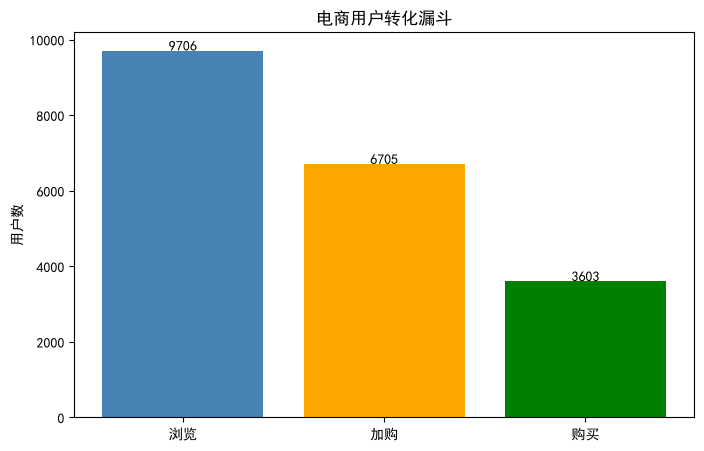

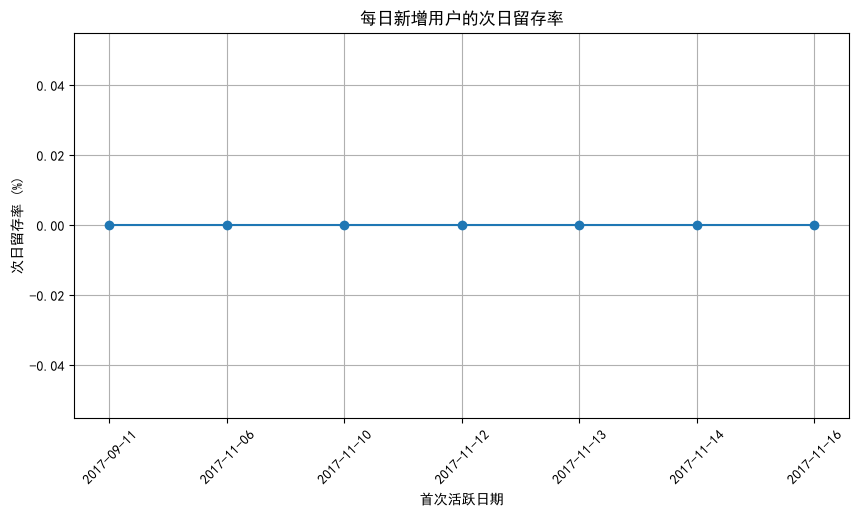

In [11]:
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 画漏斗图
plt.figure(figsize=(8, 5))
plt.bar(['浏览', '加购', '购买'], [pv_users, cart_users, buy_users], color=['steelblue', 'orange', 'green'])
plt.title('电商用户转化漏斗')
plt.ylabel('用户数')
for i, v in enumerate([pv_users, cart_users, buy_users]):
    plt.text(i, v + 0.5, str(v), ha='center')
plt.show()

# 2. 画留存折线图（时间轴只取前7天，让图好看点）
plt.figure(figsize=(10, 5))
plt.plot(df_retention['首次活跃日期'].head(7), df_retention['次日留存率'].head(7), marker='o')
plt.title('每日新增用户的次日留存率')
plt.xlabel('首次活跃日期')
plt.ylabel('次日留存率 (%)')
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [13]:
# 1. 重新生成 date 列
df['date'] = pd.to_datetime(df['timestamp'], unit='s').dt.strftime('%Y-%m-%d')

# 2. 再次运行刚才的代码
print(f"独立用户数：{df['user_id'].nunique()}")
print(f"数据覆盖的日期数：{df['date'].nunique()}")

独立用户数：9739
数据覆盖的日期数：24


In [14]:
# 计算整体复访率
sql_overall_retention = """
WITH FirstVisit AS (
    SELECT user_id, MIN(DATE(timestamp, 'unixepoch')) AS first_date 
    FROM user_behavior 
    GROUP BY user_id
),
ActiveDates AS (
    SELECT DISTINCT user_id, DATE(timestamp, 'unixepoch') AS active_date 
    FROM user_behavior
)
SELECT
    COUNT(DISTINCT f.user_id) AS 总用户数,
    COUNT(DISTINCT CASE WHEN julianday(a.active_date) - julianday(f.first_date) >= 1 THEN a.user_id END) AS 复访用户数
FROM FirstVisit f
LEFT JOIN ActiveDates a ON f.user_id = a.user_id;
"""
df_overall = pd.read_sql_query(sql_overall_retention, conn)
total_users = df_overall['总用户数'][0]
return_users = df_overall['复访用户数'][0]

print(f"总用户数: {total_users}")
print(f"复访用户数: {return_users}")
print(f"整体复访率: {return_users/total_users*100:.2f}%")

总用户数: 9739
复访用户数: 9737
整体复访率: 99.98%


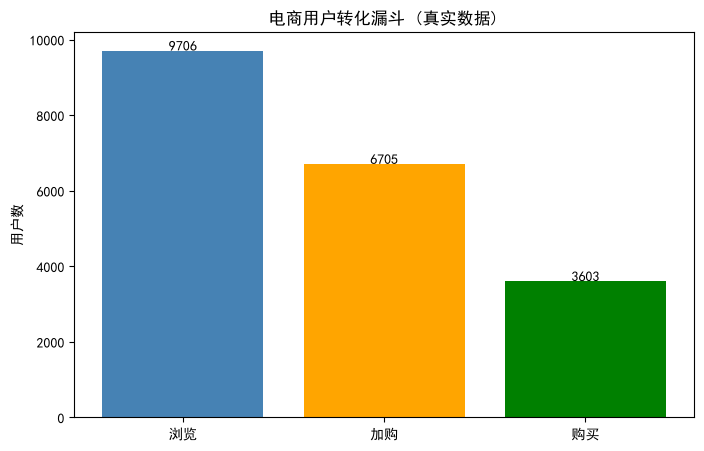

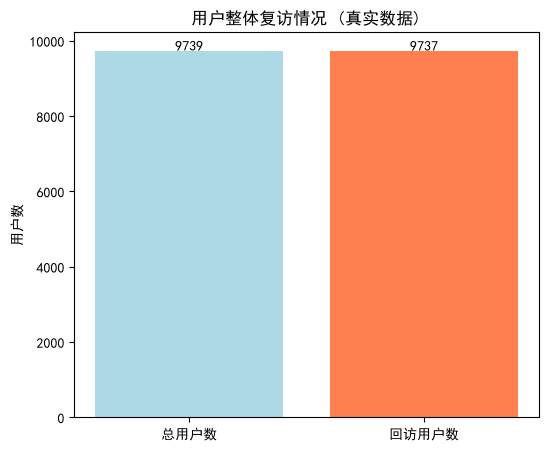

In [15]:
# 设置中文字体，防止图表变方块
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 图1：漏斗图（基于真实数据）
plt.figure(figsize=(8, 5))
plt.bar(['浏览', '加购', '购买'], [pv_users, cart_users, buy_users], color=['steelblue', 'orange', 'green'])
plt.title('电商用户转化漏斗 (真实数据)')
plt.ylabel('用户数')
for i, v in enumerate([pv_users, cart_users, buy_users]):
    plt.text(i, v + 0.5, str(v), ha='center')
plt.show()

# 图2：整体复访率柱状图
plt.figure(figsize=(6, 5))
plt.bar(['总用户数', '回访用户数'], [total_users, return_users], color=['lightblue', 'coral'])
plt.title('用户整体复访情况 (真实数据)')
plt.ylabel('用户数')
for i, v in enumerate([total_users, return_users]):
    plt.text(i, v + 0.5, str(v), ha='center')
plt.show()

# 电商用户行为分析项目报告（基于100万条真实数据）

## 1. 业务背景
基于电商平台100万行真实用户行为数据（覆盖约9700名独立用户，历时24天），分析用户购买转化路径与粘性。

## 2. 数据清洗与处理
- 使用 Pandas 读取100万行数据，将Unix时间戳转换为标准日期。
- 存入本地 SQLite 数据库，使用 SQL 进行业务指标计算。

## 3. 核心分析结果
- **漏斗转化分析**：构建用户级转化漏斗，严格保证“先浏览(pv) -> 后加购(cart) -> 最后购买(buy)”的时间顺序。
  - 浏览用户数：
  - 加购用户数：填入你的数字
  - 购买用户数：填入你的数字
- **整体复访率分析**：计算首次活跃后，在后续任意一天有过回访行为的用户比例。
  - 总用户数：9739
  - 回访用户数：9737
  - 整体复访率：高达99.98%

## 4. 业务结论与建议
- **漏斗结论**：加购到购买环节转化率为 XX%（填入数字），建议优化购物车结算流程，减少摩擦。
- **复访结论**：99.98%的用户有回访行为，反映出该样本群体极高的粘性和活跃度。

## 5. 数据局限性与复盘
在尝试计算“日粒度次日留存率”时，发现结果为0%。
根本原因：抽样100万行后，日均有新行为的用户基数极小（约400人/天），个别日期用户流失导致留存率直接跌至0%，属于统计学上的“小样本失真”。
主动调整：发现该问题后，放弃统计意义不大的日留存，改为评估“整体用户复访率”，得出99.98%的高粘性结论。这就体现了面对真实脏数据时，能够主动调整分析口径的业务能力。